DMA Start Time Interval Multi-File Comparison Analysis
Configuration:
  - Bucket size: 10 units
  - Maximum intervals to display: 80
  - Display range: 0 to 799 units

Processing all txt files in folder: .
Bucket size: 10
Maximum intervals to display: 80
Found 10 txt files in .:
   BFS_output.txt
   BS_output.txt
   GEMV_output.txt
   HST-S_output.txt
   MLP_output.txt
   NW_output.txt
   RED_output.txt
   SEL_output.txt
   TS_output.txt
   VA_output.txt

Processing: SEL_output.txt
----------------------------------------
Successfully read txt file: ./SEL_output.txt
Total lines: 770
Extracting DMA start timestamps...
Extraction complete, found 129 DMA start timestamps
Time range: 1025289 - 5718891
Calculated 128 intervals

Processing: BFS_output.txt
----------------------------------------
Successfully read txt file: ./BFS_output.txt
Total lines: 54177
Extracting DMA start timestamps...
Extraction complete, found 26898 DMA start timestamps
Time range: 508623 - 19384652
Calculated 26897

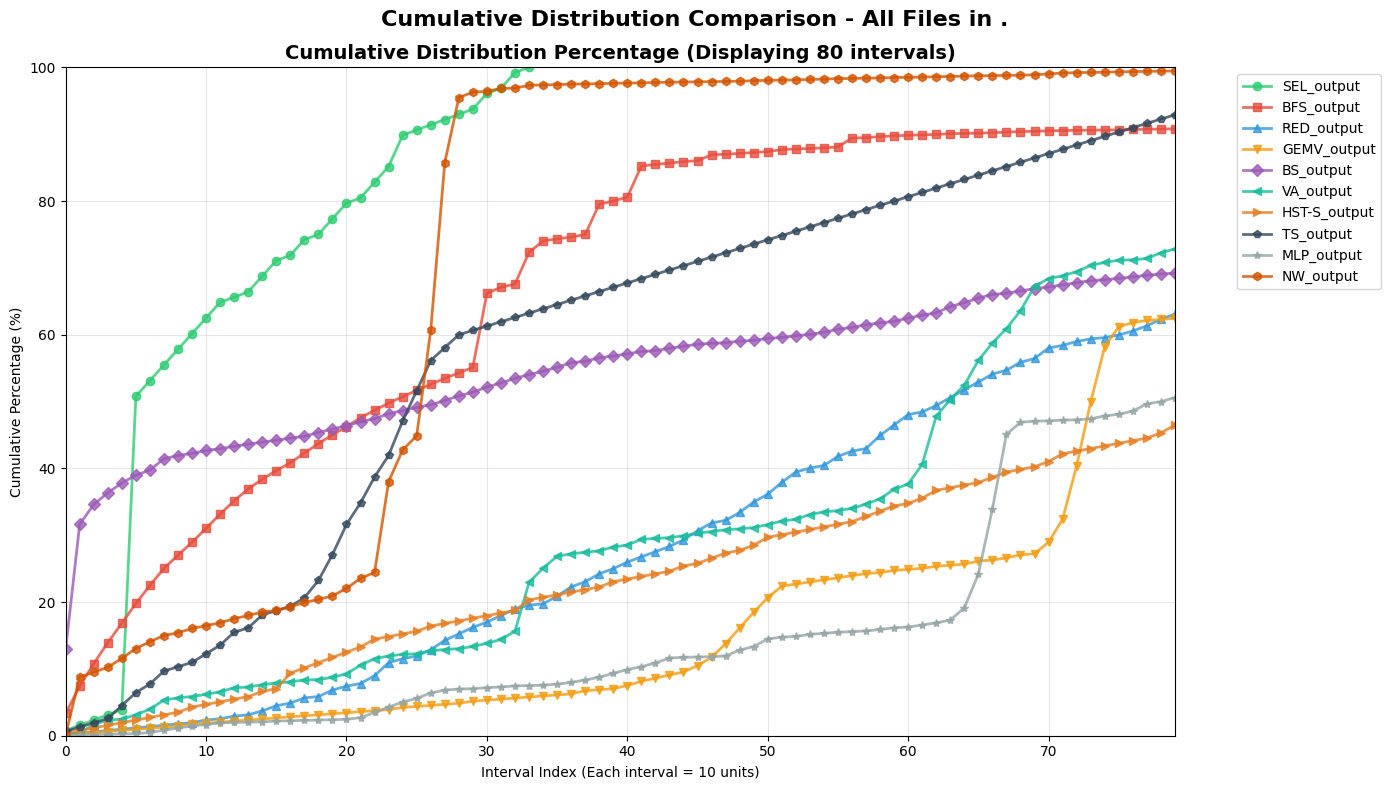


Comparison plot saved as: interval/._comparison_80intervals.png

SUMMARY STATISTICS FOR ALL FILES
Bucket size: 10 units
Display range: 0 to 799 units (80 intervals)

File: SEL_output.txt
--------------------------------------------------
Total intervals: 128
Max interval: 747,642
Key Threshold Statistics:
   Less than  100:     77 times ( 60.2%)
   Less than  200:     99 times ( 77.3%)
   Less than  300:    120 times ( 93.8%)

File: BFS_output.txt
--------------------------------------------------
Total intervals: 26,897
Max interval: 672,892
Key Threshold Statistics:
   Less than  100:   7784 times ( 28.9%)
   Less than  200:  12109 times ( 45.0%)
   Less than  300:  14823 times ( 55.1%)
   Less than  400:  21516 times ( 80.0%)
   Less than  500:  23468 times ( 87.3%)
   Less than  600:  24140 times ( 89.7%)
   Less than  700:  24325 times ( 90.4%)
   Less than  800:  24420 times ( 90.8%)

File: RED_output.txt
--------------------------------------------------
Total intervals: 512
Ma

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
from collections import Counter

# Set font for matplotlib
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

def read_txt_and_extract_start_times(txt_file_path):
    """
    Read txt file and extract all DMA start timestamps, sorted by time
    
    Args:
    txt_file_path: path to txt file
    
    Returns:
    list: sorted list of DMA start timestamps
    """
    try:
        with open(txt_file_path, 'r', encoding='utf-8') as file:
            lines = file.readlines()
        
        print(f"Successfully read txt file: {txt_file_path}")
        print(f"Total lines: {len(lines)}")
        
        start_times = []
        
        # Regex pattern to match "start dma" followed by numbers
        pattern = r'start dma (\d+)'
        
        print("Extracting DMA start timestamps...")
        
        for line_num, line in enumerate(lines, 1):
            matches = re.findall(pattern, line, re.IGNORECASE)
            
            for match in matches:
                timestamp = int(match)
                start_times.append(timestamp)
        
        # Sort by timestamp
        start_times.sort()
        print(f"Extraction complete, found {len(start_times)} DMA start timestamps")
        
        if start_times:
            print(f"Time range: {start_times[0]} - {start_times[-1]}")
        
        return start_times
        
    except Exception as e:
        print(f"Error reading txt file: {e}")
        return []

def calculate_intervals(start_times):
    """
    Calculate time interval between each start_dma and the previous start_dma
    
    Args:
    start_times: sorted list of DMA start timestamps
    
    Returns:
    list: list of time intervals
    """
    if len(start_times) < 2:
        print("Need at least 2 timestamps to calculate intervals")
        return []
    
    intervals = []
    
    for i in range(1, len(start_times)):
        interval = start_times[i] - start_times[i-1]
        intervals.append(interval)
    
    print(f"Calculated {len(intervals)} intervals")
    
    return intervals

def analyze_intervals_by_buckets(intervals, bucket_size=10):
    """
    Analyze interval distribution by specified bucket size
    
    Args:
    intervals: list of time intervals
    bucket_size: size of each bucket, default 100
    
    Returns:
    dict: dictionary containing statistical analysis results
    """
    if not intervals:
        return {}
    
    total_count = len(intervals)
    
    # Calculate max interval to determine number of buckets needed
    max_interval = max(intervals)
    num_buckets = (max_interval // bucket_size) + 1
    
    # Initialize statistical results
    stats = {
        'bucket_size': bucket_size,
        'total_count': total_count,
        'max_interval': max_interval,
        'buckets': {},
        'cumulative': {},
        'percentages': {},
        'cumulative_percentages': {}
    }
    
    # Calculate statistics for each bucket
    cumulative_count = 0
    
    for i in range(num_buckets):
        lower_bound = i * bucket_size
        upper_bound = (i + 1) * bucket_size
        
        # Calculate number of intervals in current bucket range
        if i == 0:  # First bucket includes 0
            count = sum(1 for interval in intervals if 0 <= interval <= upper_bound)
            range_str = f"[0, {upper_bound}]"
        else:
            count = sum(1 for interval in intervals if lower_bound < interval <= upper_bound)
            range_str = f"({lower_bound}, {upper_bound}]"
        
        if count > 0:  # Only record non-empty buckets
            percentage = (count / total_count) * 100
            cumulative_count += count
            cumulative_percentage = (cumulative_count / total_count) * 100
            
            stats['buckets'][range_str] = count
            stats['cumulative'][range_str] = cumulative_count
            stats['percentages'][range_str] = percentage
            stats['cumulative_percentages'][range_str] = cumulative_percentage
    
    return stats

def get_all_txt_files(folder_path):
    """
    Get all txt files in a folder
    
    Args:
    folder_path: path to folder
    
    Returns:
    list: list of txt filenames
    """
    if not os.path.exists(folder_path):
        print(f"Error: Folder {folder_path} does not exist")
        return []
    
    txt_files = [f for f in os.listdir(folder_path) if f.endswith('.txt')]
    
    print(f"Found {len(txt_files)} txt files in {folder_path}:")
    for file in sorted(txt_files):
        print(f"   {file}")
    
    return txt_files

def process_folder(folder_path, bucket_size=10):
    """
    Process all txt files in a folder and return their statistics
    
    Args:
    folder_path: path to folder
    bucket_size: size of each bucket
    
    Returns:
    dict: dictionary with filename as key and stats as value
    """
    txt_files = get_all_txt_files(folder_path)
    folder_stats = {}
    
    for filename in txt_files:
        file_path = os.path.join(folder_path, filename)
        
        print(f"\nProcessing: {filename}")
        print("-" * 40)
        
        start_times = read_txt_and_extract_start_times(file_path)
        if not start_times:
            print(f"No data found in {filename}")
            continue
        
        intervals = calculate_intervals(start_times)
        if not intervals:
            print(f"Cannot calculate intervals for {filename}")
            continue
        
        stats = analyze_intervals_by_buckets(intervals, bucket_size)
        if stats:
            folder_stats[filename] = stats
    
    return folder_stats

def create_multi_file_comparison(folder_path, bucket_size=10, max_intervals=100):
    """
    Create comparison visualization for all txt files in a folder
    
    Args:
    folder_path: path to folder containing txt files
    bucket_size: size of each bucket, default 10
    max_intervals: maximum number of intervals to display on x-axis, default 100
    """
    print(f"\nProcessing all txt files in folder: {folder_path}")
    print(f"Bucket size: {bucket_size}")
    print(f"Maximum intervals to display: {max_intervals}")
    print("="*60)
    
    # Process all files in the folder
    folder_stats = process_folder(folder_path, bucket_size)
    
    if not folder_stats:
        print("No valid data found in any files")
        return
    
    # Create comparison plot
    fig, ax = plt.subplots(1, 1, figsize=(14, 8))
    fig.suptitle(f'Cumulative Distribution Comparison - All Files in {os.path.basename(folder_path)}', 
                 fontsize=16, fontweight='bold')
    
    # Define colors for different files
    colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22', '#34495e', '#95a5a6', '#d35400']
    markers = ['o', 's', '^', 'v', 'D', '<', '>', 'p', '*', 'h']
    
    # Plot each file's cumulative distribution
    for i, (filename, stats) in enumerate(folder_stats.items()):
        if 'cumulative_percentages' in stats and stats['cumulative_percentages']:
            ranges = list(stats['cumulative_percentages'].keys())
            cum_percentages = list(stats['cumulative_percentages'].values())
            
            # Filter to show only specified number of intervals
            filtered_ranges = []
            filtered_percentages = []
            filtered_x_positions = []
            
            for j, (range_str, percentage) in enumerate(zip(ranges, cum_percentages)):
                if j < max_intervals:  # Only include up to max_intervals
                    filtered_ranges.append(range_str)
                    filtered_percentages.append(percentage)
                    filtered_x_positions.append(j)
            
            if filtered_x_positions:  # Only plot if we have data to show
                color = colors[i % len(colors)]
                marker = markers[i % len(markers)]
                
                # Use filename without extension as label
                label = os.path.splitext(filename)[0]
                
                ax.plot(filtered_x_positions, filtered_percentages, marker=marker, linestyle='-', 
                       linewidth=2, markersize=6, color=color, label=label, alpha=0.8)
    
    ax.set_title(f'Cumulative Distribution Percentage (Displaying {max_intervals} intervals)', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'Interval Index (Each interval = {bucket_size} units)')
    ax.set_ylabel('Cumulative Percentage (%)')
    ax.set_xlim(0, max_intervals - 1)
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    
    # Add legend with better formatting
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
    
    # Create interval folder if it doesn't exist
    interval_folder = "interval"
    if not os.path.exists(interval_folder):
        os.makedirs(interval_folder)
        print(f"Created folder: {interval_folder}")
    
    # Create output filename based on folder name
    folder_name = os.path.basename(folder_path.rstrip('/\\'))
    output_image_path = os.path.join(interval_folder, f"{folder_name}_comparison_{max_intervals}intervals.png")
    
    # Save the plot
    plt.tight_layout()
    plt.savefig(output_image_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nComparison plot saved as: {output_image_path}")
    
    # Print summary statistics for all files
    print_folder_summary(folder_stats, bucket_size, max_intervals)

def print_folder_summary(folder_stats, bucket_size, max_intervals):
    """
    Print summary statistics for all files in the folder
    
    Args:
    folder_stats: dictionary with filename as key and stats as value
    bucket_size: size of each bucket
    max_intervals: maximum number of intervals displayed
    """
    print(f"\n{'='*80}")
    print("SUMMARY STATISTICS FOR ALL FILES")
    print(f"Bucket size: {bucket_size} units")
    print(f"Display range: 0 to {max_intervals * bucket_size - 1} units ({max_intervals} intervals)")
    print(f"{'='*80}")
    
    for filename, stats in folder_stats.items():
        print(f"\nFile: {filename}")
        print("-" * 50)
        print(f"Total intervals: {stats['total_count']:,}")
        print(f"Max interval: {stats['max_interval']:,}")
        
        # Key threshold statistics based on bucket_size
        if stats['cumulative_percentages']:
            # Generate threshold list based on bucket_size
            thresholds = []
            for i in range(1, 11):  # Generate first 10 thresholds
                threshold = i * bucket_size * 10  # Every 10 buckets
                if threshold <= max_intervals * bucket_size:
                    thresholds.append(threshold)
            
            # Add some common thresholds if they make sense
            common_thresholds = [100, 200, 300, 500, 1000]
            for threshold in common_thresholds:
                if threshold <= max_intervals * bucket_size and threshold not in thresholds:
                    thresholds.append(threshold)
            
            thresholds = sorted(set(thresholds))
            
            if thresholds:
                print("Key Threshold Statistics:")
                
                # Calculate threshold statistics from cumulative percentages
                ranges = list(stats['cumulative_percentages'].keys())
                cum_percentages = list(stats['cumulative_percentages'].values())
                
                for threshold in thresholds:
                    bucket_index = threshold // bucket_size
                    if bucket_index <= len(cum_percentages):
                        if bucket_index == 0:
                            percentage = cum_percentages[0] if cum_percentages else 0
                        elif bucket_index > len(cum_percentages):
                            percentage = 100.0
                        else:
                            percentage = cum_percentages[bucket_index - 1]
                        
                        count = int((percentage / 100) * stats['total_count'])
                        print(f"   Less than {threshold:>4}: {count:>6} times ({percentage:>5.1f}%)")

def main():
    """
    Main function: execute multi-file comparison analysis workflow
    """
    # Get user input
    folder_path = "."
    
    # 用户可以在这里自定义参数
    bucket_size = 10         # 每个桶的大小（单位）
    max_intervals = 80     # 显示的最大间隔数量
    
    print("DMA Start Time Interval Multi-File Comparison Analysis")
    print("="*60)
    print(f"Configuration:")
    print(f"  - Bucket size: {bucket_size} units")
    print(f"  - Maximum intervals to display: {max_intervals}")
    print(f"  - Display range: 0 to {max_intervals * bucket_size - 1} units")
    print("="*60)
    
    # Process the folder and create comparison
    create_multi_file_comparison(folder_path, bucket_size, max_intervals)
    
    print("\nAnalysis complete!")

# 额外添加一个便捷函数，可以直接调用来指定参数
def analyze_with_custom_settings(folder_path=".", bucket_size=10, max_intervals=100):
    """
    便捷函数：使用自定义设置进行分析
    
    Args:
    folder_path: 文件夹路径，默认当前目录
    bucket_size: 桶大小，默认10
    max_intervals: 最大显示间隔数，默认100
    """
    print("DMA Start Time Interval Analysis with Custom Settings")
    print("="*60)
    print(f"Configuration:")
    print(f"  - Folder path: {folder_path}")
    print(f"  - Bucket size: {bucket_size} units")
    print(f"  - Maximum intervals to display: {max_intervals}")
    print(f"  - Display range: 0 to {max_intervals * bucket_size - 1} units")
    print("="*60)
    
    create_multi_file_comparison(folder_path, bucket_size, max_intervals)
    
    print("\nAnalysis complete!")

if __name__ == "__main__":
    main()
    
    # 示例：如果你想使用不同的设置，可以取消注释下面的行
    # analyze_with_custom_settings(folder_path=".", bucket_size=2, max_intervals=500)
    # analyze_with_custom_settings(folder_path=".", bucket_size=20, max_intervals=50)